# STM metro incidents: analysis notebook

This notebook is the narrative of the analysis. Reusable code lives in `src/`;
the cells here call it and show the evidence.

**Part 1 (this section): exploration.** Its only purpose is to inform two later
decisions: how to define a major interruption (target) and which fields can be
used to predict it (features). No target, feature set or model is chosen here.

## 0. Setup

In [1]:
import sys
from pathlib import Path

# Make the repository root importable, whether the notebook is run from the
# repository root or from the notebooks/ folder.
REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO_ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src import data, eda, verify

pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_rows", 100)
print("Python interpreter:", sys.executable)

Python interpreter: /Users/elcinergin/Library/Mobile Documents/com~apple~CloudDocs/Learn_Apply/2026_JobApplication/TobogganLabs/takehome/DS_challenge/.venv.nosync/bin/python


In [2]:
# Rebuild the cleaned tables from the raw files, so the notebook always starts
# from raw data. The raw tables are loaded too, for the verification checks.
incidents, km = data.build()
incidents_raw = data.load_incidents_raw()
km_raw = data.load_km_raw()

# Most of the exploration looks at train incidents (see section 1 for why).
train = eda.train_incidents(incidents)
print(f"{len(incidents):,} incidents, of which {len(train):,} train incidents")
print(f"{len(km):,} planned-km rows")

45,561 incidents, of which 29,167 train incidents
8,472 planned-km rows


## 1. Verifying the initial observations

`PLAN.md` lists observations made during a first quick look at the files. Each
one is re-checked here with an explicit test. `CORRECTED` means the first
impression was wrong or incomplete; `from dictionary` means the statement comes
from the data dictionary and cannot be tested with the data.

In [3]:
checks = verify.verify_observations(incidents_raw, km_raw, incidents, km)
print(checks["status"].value_counts().to_string())
checks

status
confirmed          23
CORRECTED           5
from dictionary     5


,observation,check,expected,found,status
0,"Both .xls files are plain text, not Excel workbooks",first bytes are an Excel signature,False,False,confirmed
1,"Incidents file: 45,561 rows x 26 columns",shape of the raw table,"(45561, 26)","(45561, 26)",confirmed
2,"Planned-km file: 8,472 rows x 11 columns",shape of the raw table,"(8472, 11)","(8472, 11)",confirmed
3,"Incidents file starts with a byte-order mark, km file does not",first three bytes of each file,"(True, False)","(True, False)",confirmed
4,Exactly one line value is corrupted (02-avr),values of `line` that are not a line,['02-avr'],['02-avr'],confirmed
5,Year/month is stored as text such as janv-19,share of values shaped like letters-two digits,1.0,1.0,confirmed
6,Times run from 02:00 to 27:41,"earliest start time and latest end time, as hours:minutes",2:00 to 27:41,2:00 to 29:30,CORRECTED
7,Times mix HH:MM and HH:MM:SS formats,text lengths found in the start time,"[5, 8]","[5, 8]",confirmed
8,"Year, month, day and weekday follow the service day",share of rows where weekday matches the service date,1.0,1.0,confirmed
9,Calendar date is one day later exactly when the start time is past 24:00,rows with a later calendar date but a start time before 24:00,0,60,CORRECTED


**The five corrections**

1. Times run to 29:30, not 27:41 (the first look only covered train incidents).
2. The calendar date is one day after the service date for every incident
   starting at 24:00 or later, as expected, but also for 60 incidents that start
   at exactly `02:00`. These look like incidents at the very end of the service
   day, written as 02:00 instead of 26:00.
3. Zero-km duplicate rows also exist in 2020 (76 rows), not only in 2019.
4. The zero-km row is not always the one without a service period: for 868
   line/days the planned km sits on the row without a period.
5. Rolling stock type mirrors the secondary cause in all but 4 rows.

In [4]:
# Correction 5 in detail: rolling stock type against secondary cause.
pd.crosstab(
    incidents["rolling_stock_type"],
    incidents["secondary_cause"].where(
        incidents["secondary_cause"].isin(["MR-73", "MPM-10"]), "any other cause"
    ),
)

secondary_cause,MPM-10,MR-73,any other cause
rolling_stock_type,,,
10,1226,0,4
73,0,2915,0
Non affecté,0,0,41416


## 2. Evidence for the target decision

### 2.1 Why train incidents

Every station incident sits in the lowest duration bin, and the dictionary
states that station incidents do not affect metro service. Duration therefore
only varies among train incidents.

In [5]:
pd.crosstab(incidents["duration_bin"], incidents["incident_type"], margins=True)

incident_type,S,T,All
duration_bin,,,
02 min et moins,16394,16450,32844
03 à 04 min,0,6304,6304
05 à 09 min,0,4377,4377
10 à 14 min,0,933,933
15 à 19 min,0,299,299
20 à 24 min,0,173,173
25 à 29 min,0,107,107
30 min et plus,0,524,524
All,16394,29167,45561


### 2.2 How long train incidents last, and is that stable over time?

The table gives, per year, the number of train incidents and the share lasting
at least 5, 10 and 30 minutes. 2025 covers January to September only.

In [6]:
by_year = eda.duration_summary(train, "service_year")
# Number of incidents behind each share, to judge how noisy each one is.
for minutes in eda.THRESHOLDS:
    by_year[f"n_{minutes}min_plus"] = (
        by_year[f"share_{minutes}min_plus"] * by_year["incidents"]
    ).round().astype(int)
by_year.style.format({c: "{:.1%}" for c in by_year.columns if c.startswith("share")})

,incidents,share_5min_plus,share_10min_plus,share_30min_plus,n_5min_plus,n_10min_plus,n_30min_plus
service_year,,,,,,,
2019,5081,19.0%,5.4%,1.3%,964,275,67
2020,3709,21.5%,6.8%,2.1%,799,253,77
2021,3564,22.4%,7.4%,2.1%,800,262,75
2022,4207,21.3%,6.6%,1.9%,896,276,78
2023,4497,24.4%,7.7%,1.6%,1097,345,71
2024,5063,22.1%,7.8%,2.0%,1121,396,102
2025,3046,24.2%,7.5%,1.8%,736,229,54


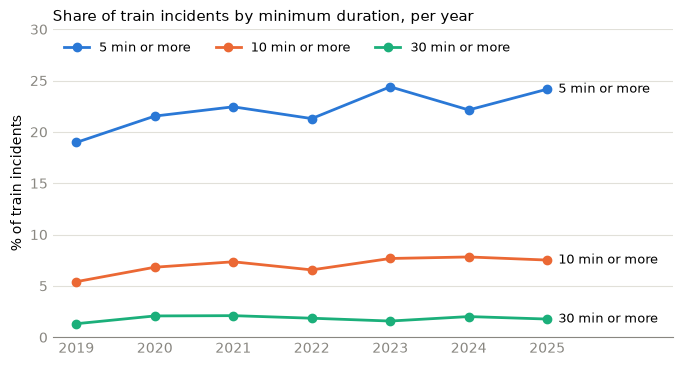

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
labels = {5: "5 min or more", 10: "10 min or more", 30: "30 min or more"}
for minutes, color in zip(eda.THRESHOLDS, eda.SERIES_COLORS):
    share = by_year[f"share_{minutes}min_plus"] * 100
    ax.plot(share.index, share, color=color, linewidth=2, marker="o", label=labels[minutes])
    # Direct label at the end of each line.
    ax.annotate(labels[minutes], (share.index[-1], share.iloc[-1]),
                xytext=(8, 0), textcoords="offset points", va="center", fontsize=9)
ax.set_ylim(0, 30)
ax.set_xlim(2018.7, 2026.6)
ax.set_xticks(by_year.index)
eda.style_axes(ax, "Share of train incidents by minimum duration, per year", "% of train incidents")
ax.legend(frameon=False, loc="upper left", ncol=3, fontsize=9)
plt.show()

In [8]:
# Same summary by line. Combinations of lines are grouped together.
by_line = eda.duration_summary(train, "line_group")
by_line.style.format({c: "{:.1%}" for c in by_line.columns if c.startswith("share")})

,incidents,share_5min_plus,share_10min_plus,share_30min_plus
line_group,,,,
Ligne bleue,3232,22.1%,6.3%,1.6%
Ligne jaune,2153,19.5%,5.3%,0.9%
Ligne orange,11506,21.3%,6.3%,1.6%
Ligne verte,11827,22.7%,7.4%,1.7%
Multiple lines or other,449,32.3%,24.1%,13.8%


### 2.3 Volume over time

Monthly train incidents, all durations (top) and 5 minutes or more (bottom).
The dashed line marks March 2020 (start of COVID-19 restrictions); the shaded
band marks the last three months of data, which the dictionary says can still
be incomplete.

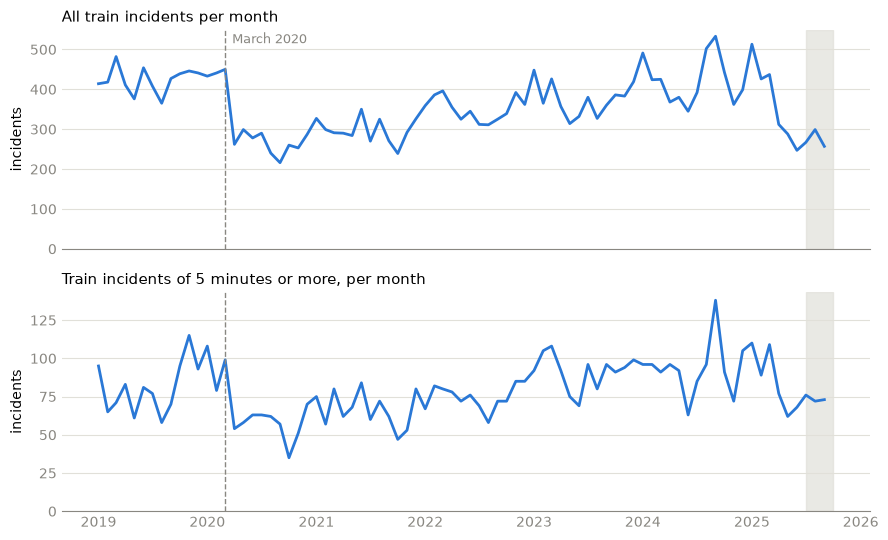

In [9]:
# One row per month: count all train incidents and those of 5 minutes or more.
train["month_start"] = train["service_date"].dt.to_period("M").dt.to_timestamp()
monthly = train.groupby("month_start").agg(
    incidents=("incident_id", "size"),
    incidents_5min_plus=("duration_bin_lower", lambda s: (s >= 5).sum()),
)

fig, axes = plt.subplots(2, 1, figsize=(9, 5.5), sharex=True)
titles = {"incidents": "All train incidents per month",
          "incidents_5min_plus": "Train incidents of 5 minutes or more, per month"}
last_month = monthly.index.max()
for ax, column in zip(axes, titles):
    ax.plot(monthly.index, monthly[column], color=eda.SERIES_COLORS[0], linewidth=2)
    ax.axvline(pd.Timestamp("2020-03-01"), color=eda.MUTED_COLOR, linestyle="--", linewidth=1)
    ax.axvspan(last_month - pd.DateOffset(months=2), last_month + pd.DateOffset(months=1),
               color=eda.GRID_COLOR, alpha=0.7)
    ax.set_ylim(0, None)
    eda.style_axes(ax, titles[column], "incidents")
axes[0].annotate("March 2020", (pd.Timestamp("2020-03-01"), monthly["incidents"].max()),
                 xytext=(5, -5), textcoords="offset points", fontsize=9, color=eda.MUTED_COLOR)
plt.tight_layout()
plt.show()

In [10]:
# Table behind the figure, summarised per year (monthly average), plus the
# last six months compared with the same months one year earlier.
print(monthly.groupby(monthly.index.year).mean().round(0).rename_axis("year").to_string())

last_six = monthly.tail(6).copy()
same_months_last_year = monthly.loc[last_six.index - pd.DateOffset(years=1), "incidents"]
last_six["incidents_one_year_earlier"] = same_months_last_year.to_numpy()
last_six

      incidents  incidents_5min_plus
year                                
2019      423.0                 80.0
2020      309.0                 67.0
2021      297.0                 67.0
2022      351.0                 75.0
2023      375.0                 91.0
2024      422.0                 93.0
2025      338.0                 82.0


,incidents,incidents_5min_plus,incidents_one_year_earlier
month_start,,,
2025-04-01,312,77,368
2025-05-01,288,62,380
2025-06-01,247,68,345
2025-07-01,267,76,392
2025-08-01,299,72,502
2025-09-01,257,73,533


The last six months are well below the same months one year earlier. To see
whether that is a general drop or limited to short incidents, the next table
counts April to September of each year, split by duration.

In [11]:
# April to September of each year: short incidents against 5 minutes or more.
spring_summer = train[train["service_month"].between(4, 9)]
april_september = spring_summer.groupby("service_year").agg(
    under_5min=("duration_bin_lower", lambda s: (s < 5).sum()),
    five_min_plus=("duration_bin_lower", lambda s: (s >= 5).sum()),
)
april_september["share_5min_plus"] = (
    april_september["five_min_plus"] / april_september.sum(axis=1)
).round(3)
april_september

,under_5min,five_min_plus,share_5min_plus
service_year,,,
2019,2011,430,0.176
2020,1228,357,0.225
2021,1382,408,0.228
2022,1548,425,0.215
2023,1562,508,0.245
2024,1950,570,0.226
2025,1242,428,0.256


### 2.4 Reliability view: incidents per million planned km

Raw counts mix reliability with how much service was run. Dividing by planned
kilometres separates the two. This is only possible where km data exists
(January 2019 to September 2023) and for incidents assigned to a single line.
2023 covers January to September for both incidents and km.

In [12]:
# Coverage of the km denominator.
last_km_date = data.daily_km(km)["calendar_date"].max()
in_km_period = train["service_date"] <= last_km_date
on_single_line = train["line"].isin(data.SINGLE_LINES)
print(f"Train incidents in the km period: {in_km_period.mean():.1%}")
print(f"Train incidents on a single line: {on_single_line.mean():.1%}")
print(f"Train incidents with a km denominator (both): {(in_km_period & on_single_line).mean():.1%}")

rates = eda.incidents_per_million_km(train, km)
assert rates["incidents"].sum() == (in_km_period & on_single_line).sum()   # reconciles
rates.round(1)

Train incidents in the km period: 68.1%
Train incidents on a single line: 98.5%
Train incidents with a km denominator (both): 67.2%


incidents  incidents_5min_plus  million_km  \
year line                                                       
2019 Ligne bleue         604                  112         8.4   
     Ligne jaune         382                   51         4.9   
     Ligne orange       2082                  380        44.0   
     Ligne verte        1948                  399        32.6   
2020 Ligne bleue         436                   83         8.3   
     Ligne jaune         213                   35         4.8   
     Ligne orange       1492                  300        42.8   
     Ligne verte        1521                  372        32.2   
2021 Ligne bleue         341                   71         7.9   
     Ligne jaune         194                   42         4.6   
     Ligne orange       1493                  329        41.1   
     Ligne verte        1486                  338        30.8   
2022 Ligne bleue         480                  114         7.9   
     Ligne jaune         293                   42         4.6   
     Ligne orange       1613                  331        41.1   
     Ligne verte        1777                  405        30.8   
2023 Ligne bleue         345                   81         5.7   
     Ligne jaune         221                   43         4.6   
     Ligne orange       1196                  295        29.8   
     Ligne verte        1495                  380        21.4   

                   incidents_per_million_km  \
year line                                     
2019 Ligne bleue                       71.5   
     Ligne jaune                       78.0   
     Ligne orange                      47.3   
     Ligne verte                       59.8   
2020 Ligne bleue                       52.5   
     Ligne jaune                       44.8   
     Ligne orange                      34.9   
     Ligne verte                       47.3   
2021 Ligne bleue                       43.4   
     Ligne jaune                       42.6   
     Ligne orange                      36.3   
     Ligne verte                       48.2   
2022 Ligne bleue                       61.0   
     Ligne jaune                       64.3   
     Ligne orange                      39.2   
     Ligne verte                       57.7   
2023 Ligne bleue                       60.0   
     Ligne jaune                       48.5   
     Ligne orange                      40.1   
     Ligne verte                       69.8   

                   incidents_5min_plus_per_million_km  
year line                                              
2019 Ligne bleue                                 13.3  
     Ligne jaune                                 10.4  
     Ligne orange                                 8.6  
     Ligne verte                                 12.3  
2020 Ligne bleue                                 10.0  
     Ligne jaune                                  7.4  
     Ligne orange                                 7.0  
     Ligne verte                                 11.6  
2021 Ligne bleue                                  9.0  
     Ligne jaune                                  9.2  
     Ligne orange                                 8.0  
     Ligne verte                                 11.0  
2022 Ligne bleue                                 14.5  
     Ligne jaune                                  9.2  
     Ligne orange                                 8.0  
     Ligne verte                                 13.1  
2023 Ligne bleue                                 14.1  
     Ligne jaune                                  9.4  
     Ligne orange                                 9.9  
     Ligne verte                                 17.7

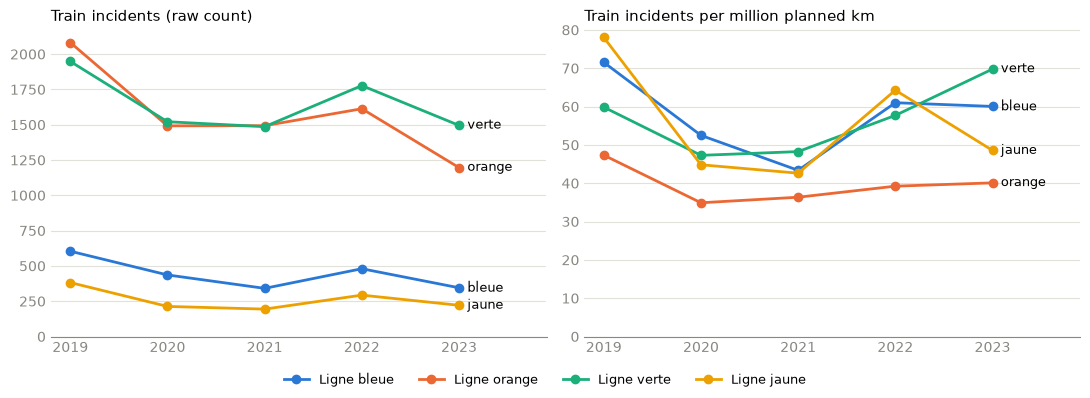

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True)
panels = {"incidents": "Train incidents (raw count)",
          "incidents_per_million_km": "Train incidents per million planned km"}
for ax, column in zip(axes, panels):
    for line, color in eda.LINE_COLORS.items():
        series = rates.xs(line, level="line")[column]
        ax.plot(series.index, series, color=color, linewidth=2, marker="o", label=line)
        ax.annotate(line.replace("Ligne ", ""), (series.index[-1], series.iloc[-1]),
                    xytext=(6, 0), textcoords="offset points", va="center", fontsize=9)
    ax.set_ylim(0, None)
    ax.set_xlim(2018.8, 2023.9)
    ax.set_xticks(range(2019, 2024))
    eda.style_axes(ax, panels[column])
handles, names = axes[0].get_legend_handles_labels()
fig.legend(handles, names, frameon=False, fontsize=9, ncol=4, loc="lower center")
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

In [14]:
# Planned km per line and year, to read the rates against. 2023 has 9 months.
planned = data.daily_km(km)
planned["year"] = planned["calendar_date"].dt.year
km_table = (planned.groupby(["year", "line"])["planned_km"].sum() / 1e6).unstack().round(2)
km_table["days"] = planned.groupby("year")["calendar_date"].nunique()
km_table

line,Ligne bleue,Ligne jaune,Ligne orange,Ligne verte,days
year,,,,,
2019,8.44,4.90,44.00,32.55,365
2020,8.31,4.75,42.76,32.18,366
2021,7.87,4.55,41.08,30.80,365
2022,7.87,4.56,41.12,30.80,365
2023,5.75,4.55,29.84,21.42,273


Planned km on the yellow line are about a third higher per day in 2023 than in
2022, which pulls its 2023 rate down. The data cannot say whether service
really increased or the planning figures changed.

In [15]:
# Average planned km per day, by line and year.
planned.groupby(["year", "line"])["planned_km"].mean().unstack().round(0)

line,Ligne bleue,Ligne jaune,Ligne orange,Ligne verte
year,,,,
2019,23134.0,13413.0,120559.0,89181.0
2020,22700.0,12987.0,116829.0,87920.0
2021,21548.0,12473.0,112554.0,84389.0
2022,21558.0,12490.0,112668.0,84388.0
2023,21050.0,16674.0,109288.0,78477.0


### 2.5 Hypothesis: are some time/bin mismatches closures logged as incidents?

525 train incidents have an elapsed time (end minus start) outside their
duration bin. If some of these are long closures recorded as an incident with
a short service delay, they should cluster at specific places and dates.
The Saint-Michel station closure in fall 2024 is one candidate.

In [16]:
mismatch = train[train["flag_time_bin_mismatch"]].copy()
print(f"Mismatches: {len(mismatch)} ({len(mismatch) / len(train):.1%} of train incidents)")

# How long is the gap between start and end for these rows?
gap_bands = pd.cut(mismatch["elapsed_minutes"], [-1, 29, 59, 179, 5000],
                   labels=["under 30 min", "30 to 59 min", "1 to 3 hours", "3 hours or more"])
print(gap_bands.value_counts().sort_index().to_string())

Mismatches: 525 (1.8% of train incidents)
elapsed_minutes
under 30 min       384
30 to 59 min        75
1 to 3 hours        45
3 hours or more     21


In [17]:
# The very long ones (3 hours or more): where and when?
long_gap = mismatch[mismatch["elapsed_minutes"] >= 180].copy()
long_gap["month"] = long_gap["service_date"].dt.strftime("%Y-%m")
print(long_gap.groupby(["location", "month"]).size().sort_values(ascending=False).head(12).to_string())
long_gap[["incident_id", "service_date", "location", "start_time_raw", "end_time_raw",
          "duration_bin", "symptom", "primary_cause"]].sort_values("service_date").tail(15)

location                       month  
St-Michel                      2024-10    6
ARRIERE-GARE COTE-VERTU        2023-03    1
ARRIERE-GARE HONORE-BEAUGRAND  2021-03    1
Berri L-2                      2025-08    1
Berri-UQAM                     2020-04    1
Charlevoix                     2024-04    1
Crémazie/Sauvé                 2025-01    1
De l'Eglise                    2024-01    1
GARAGE MONTMORENCY             2023-12    1
Garage Angrignon               2024-10    1
Radisson                       2024-01    1
Sauvé/Henri-Bourassa           2022-05    1


,incident_id,service_date,location,start_time_raw,end_time_raw,duration_bin,symptom,primary_cause
38551,T24012413,2024-01-24,Radisson,19:44,23:16,03 à 04 min,Clientèle,Clientèle
39519,T25012413,2024-01-25,De l'Eglise,22:49,27:14:00,02 min et moins,Clientèle,Clientèle
30828,T16022401,2024-02-16,Villa-Maria,05:25,10:16,02 min et moins,Exploitation stations,Autres
33922,T19042403,2024-04-19,Charlevoix,07:50,15:20,05 à 09 min,Équipements fixes,Équipements fixes
29262,T14062401,2024-06-14,Snowdon,05:30,08:46,05 à 09 min,Équipements fixes,Équipements fixes
20042,T04102417,2024-10-04,St-Michel,05:30,24:30:00,02 min et moins,Équipements fixes,Équipements fixes
21049,T05102411,2024-10-05,St-Michel,05:30,24:30:00,02 min et moins,Équipements fixes,Équipements fixes
21982,T06102409,2024-10-06,St-Michel,05:30,24:30:00,02 min et moins,Équipements fixes,Équipements fixes
22911,T07102411,2024-10-07,St-Michel,05:30,24:30:00,02 min et moins,Équipements fixes,Équipements fixes
23858,T08102404,2024-10-08,St-Michel,05:30,24:30:00,02 min et moins,Équipements fixes,Équipements fixes


In [18]:
# All mismatches: top locations, and mismatches per year next to all train incidents.
print(mismatch["location"].value_counts().head(8).to_string())
pd.DataFrame({
    "train_incidents": train.groupby("service_year").size(),
    "mismatches": mismatch.groupby("service_year").size(),
}).assign(share=lambda t: (t["mismatches"] / t["train_incidents"]).round(3))

location
Berri-UQAM           33
Lionel-Groulx        18
Beaudry              17
St-Michel            17
Papineau             15
Frontenac            13
Honorée-Beaugrand    12
Joliette             11


,train_incidents,mismatches,share
service_year,,,
2019,5081,59,0.012
2020,3709,60,0.016
2021,3564,61,0.017
2022,4207,75,0.018
2023,4497,88,0.020
2024,5063,115,0.023
2025,3046,67,0.022


## 3. Evidence for the feature decision

### 3.1 When is each field known, and how strongly does it relate to duration?

For each value of each candidate field: number of train incidents and the share
lasting at least 5, 10 and 30 minutes. A field that is strongly related to
duration is only useful if it is known when the incident starts; the dictionary
does not say when the operational indicators are recorded.

In [19]:
# Two extra yes/no columns: was a train run / a vehicle recorded?
train["has_run_number"] = train["run_number"].notna()
train["has_vehicle"] = train["vehicle"].notna()

# What the data dictionary says about when each field is recorded.
timing = {
    "symptom": "at the time of the incident (dictionary)",
    "line_group": "not documented",
    "traction_power_cut": "not documented",
    "emergency_team": "not documented",
    "evacuation": "not documented",
    "material_damage": "not documented",
    "emergency_brake": "not documented",
    "door_involved": "not documented",
    "has_run_number": "not documented",
    "has_vehicle": "not documented",
    "primary_cause": "after analysis (dictionary)",
    "rolling_stock_type": "mirrors secondary cause, so after analysis",
}

pieces = []
for field, when in timing.items():
    summary = eda.duration_summary(train, field).reset_index()
    summary = summary.rename(columns={field: "value"})
    summary.insert(0, "field", field)
    summary["recorded"] = when
    pieces.append(summary)
field_table = pd.concat(pieces, ignore_index=True)

overall = eda.duration_summary(train.assign(all="all train incidents"), "all")
print(overall.round(3).to_string())
field_table.style.format({c: "{:.1%}" for c in field_table.columns if c.startswith("share")})

                     incidents  share_5min_plus  share_10min_plus  share_30min_plus
all                                                                                
all train incidents      29167             0.22              0.07             0.018


,field,value,incidents,share_5min_plus,share_10min_plus,share_30min_plus,recorded
0,symptom,Clientèle,13095,19.4%,6.4%,1.7%,at the time of the incident (dictionary)
1,symptom,Divers,97,34.0%,12.4%,2.1%,at the time of the incident (dictionary)
2,symptom,Exploitation stations,944,1.1%,0.5%,0.2%,at the time of the incident (dictionary)
3,symptom,Exploitation trains,2071,10.5%,0.8%,0.0%,at the time of the incident (dictionary)
4,symptom,"Feu, fumée, odeur, produit, etc...",1250,20.4%,17.4%,11.0%,at the time of the incident (dictionary)
5,symptom,Matériel roulant,7750,26.4%,6.5%,0.7%,at the time of the incident (dictionary)
6,symptom,Équipements fixes,3877,33.4%,11.2%,2.7%,at the time of the incident (dictionary)
7,line_group,Ligne bleue,3232,22.1%,6.3%,1.6%,not documented
8,line_group,Ligne jaune,2153,19.5%,5.3%,0.9%,not documented
9,line_group,Ligne orange,11506,21.3%,6.3%,1.6%,not documented


### 3.2 Data quality of candidate fields over time

Share of train incidents with a missing value per year, and the mix of symptom
categories per year. A field whose recording changes over time is risky as a
predictor, because the model would learn the reporting practice.

In [20]:
fields = ["symptom", "primary_cause", "run_number", "vehicle"]
missing_by_year = train.groupby("service_year")[fields].agg(lambda s: s.isna().mean())
missing_by_year.style.format("{:.1%}")

,symptom,primary_cause,run_number,vehicle
service_year,,,,
2019,0.0%,1.2%,14.7%,59.6%
2020,0.1%,1.6%,18.4%,60.2%
2021,0.2%,1.8%,18.0%,63.3%
2022,0.4%,1.5%,19.0%,60.3%
2023,0.5%,1.8%,19.7%,62.1%
2024,0.4%,1.9%,19.7%,56.8%
2025,0.4%,1.8%,23.0%,60.7%


In [21]:
# Symptom mix per year (each row sums to 100%). Missing symptoms shown as their own column.
symptom_mix = pd.crosstab(train["service_year"], train["symptom"].fillna("(missing)"),
                          normalize="index")
symptom_mix.style.format("{:.1%}")

symptom,(missing),Clientèle,Divers,Exploitation stations,Exploitation trains,"Feu, fumée, odeur, produit, etc...",Matériel roulant,Équipements fixes
service_year,,,,,,,,
2019,0.0%,40.7%,0.5%,0.8%,12.3%,4.7%,29.2%,11.8%
2020,0.1%,42.3%,0.1%,1.0%,9.3%,4.9%,30.4%,11.8%
2021,0.2%,45.6%,0.7%,2.2%,7.3%,5.4%,22.7%,16.0%
2022,0.4%,46.3%,0.5%,3.1%,6.1%,4.6%,25.3%,13.7%
2023,0.5%,48.3%,0.2%,3.4%,4.9%,3.9%,24.1%,14.8%
2024,0.4%,44.9%,0.2%,4.7%,4.0%,3.4%,28.9%,13.4%
2025,0.4%,47.1%,0.1%,8.8%,5.4%,3.3%,23.6%,11.4%


In [22]:
# Operational indicators per year: share of train incidents where each is set.
indicators = ["traction_power_cut", "emergency_team", "material_damage",
              "emergency_brake", "door_involved"]
indicator_by_year = train.groupby("service_year")[indicators].mean()
indicator_by_year["any_evacuation"] = train.groupby("service_year")["evacuation"].apply(
    lambda s: (s != "Aucune").mean()
)
indicator_by_year.style.format("{:.1%}")

,traction_power_cut,emergency_team,material_damage,emergency_brake,door_involved,any_evacuation
service_year,,,,,,
2019,24.1%,1.4%,1.0%,3.5%,14.1%,4.5%
2020,22.4%,1.7%,1.2%,3.0%,13.7%,5.7%
2021,26.0%,2.1%,1.6%,3.7%,8.3%,6.1%
2022,24.7%,1.5%,1.2%,3.7%,9.5%,4.5%
2023,25.7%,1.6%,1.1%,3.6%,9.7%,4.0%
2024,22.5%,1.7%,1.2%,3.4%,6.4%,4.1%
2025,24.0%,1.6%,1.2%,4.6%,7.5%,4.5%


### 3.3 Time and location

One compact view each: hour of the service day, day of week, and location.

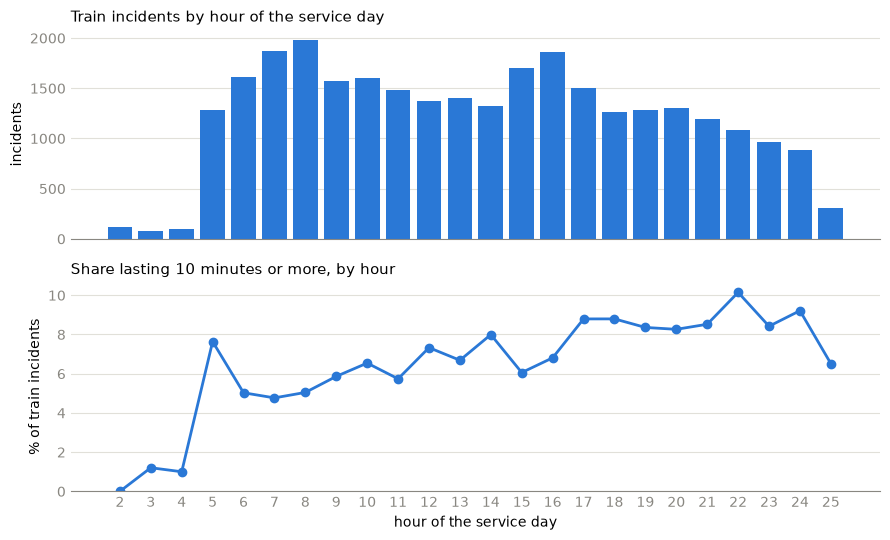

,incidents,share_5min_plus,share_10min_plus,share_30min_plus
start_hour,,,,
2,121,0.0%,0.0%,0.0%
3,83,1.2%,1.2%,0.0%
4,100,1.0%,1.0%,1.0%
5,1283,18.6%,7.6%,2.6%
6,1611,19.6%,5.0%,1.3%
7,1867,19.8%,4.8%,0.8%
8,1982,21.3%,5.0%,1.3%
9,1569,20.8%,5.9%,1.5%
10,1605,24.0%,6.5%,1.4%


In [23]:
# Hour of the service day (hours 24 and 25 are after midnight).
train["start_hour"] = train["start_minutes"] // 60
by_hour = eda.duration_summary(train, "start_hour")

fig, axes = plt.subplots(2, 1, figsize=(9, 5.5), sharex=True)
axes[0].bar(by_hour.index, by_hour["incidents"], color=eda.SERIES_COLORS[0], width=0.8)
eda.style_axes(axes[0], "Train incidents by hour of the service day", "incidents")
axes[1].plot(by_hour.index, by_hour["share_10min_plus"] * 100,
             color=eda.SERIES_COLORS[0], linewidth=2, marker="o")
axes[1].set_ylim(0, None)
axes[1].set_xticks(by_hour.index)
axes[1].set_xlabel("hour of the service day")
eda.style_axes(axes[1], "Share lasting 10 minutes or more, by hour", "% of train incidents")
plt.tight_layout()
plt.show()
by_hour.style.format({c: "{:.1%}" for c in by_hour.columns if c.startswith("share")})

In [24]:
# Day of week (1 = Monday ... 7 = Sunday), based on the service date.
by_weekday = eda.duration_summary(train, "weekday")
by_weekday.style.format({c: "{:.1%}" for c in by_weekday.columns if c.startswith("share")})

,incidents,share_5min_plus,share_10min_plus,share_30min_plus
weekday,,,,
1,4294,21.8%,6.8%,1.9%
2,4591,22.2%,6.2%,1.5%
3,4334,21.1%,7.2%,1.8%
4,4443,22.3%,7.1%,2.2%
5,4708,21.9%,6.8%,1.6%
6,3525,21.8%,7.1%,1.8%
7,3272,23.0%,7.8%,1.8%


In [25]:
# Location: how concentrated are incidents, and do locations differ in duration?
location_counts = train["location"].value_counts()
print(f"Distinct locations among train incidents: {len(location_counts)}")
print(f"Locations with fewer than 30 train incidents: {(location_counts < 30).sum()}")
print(f"Share of train incidents in the 15 busiest locations: {location_counts.head(15).sum() / len(train):.1%}")

by_location = eda.duration_summary(train, "location").sort_values("incidents", ascending=False)
by_location.head(15).style.format({c: "{:.1%}" for c in by_location.columns if c.startswith("share")})

Distinct locations among train incidents: 229
Locations with fewer than 30 train incidents: 118
Share of train incidents in the 15 busiest locations: 45.3%


,incidents,share_5min_plus,share_10min_plus,share_30min_plus
location,,,,
Berri-UQAM,2231,15.6%,3.4%,0.4%
Montmorency,1286,10.1%,1.2%,0.3%
Côte-Vertu,974,10.8%,2.1%,0.3%
Snowdon,963,14.7%,3.6%,0.5%
Angrignon,949,15.4%,3.0%,0.2%
Honorée-Beaugrand,943,17.3%,3.6%,1.0%
Berri L-2,840,15.1%,2.3%,0.2%
Lionel-Groulx,783,17.5%,4.7%,1.0%
Longueuil,767,13.2%,3.7%,1.2%


## 4. Findings from the exploration

Each finding is tagged **solid** (directly supported by the data),
**tentative** (a pattern with more than one possible explanation) or
**not answerable** (the data cannot settle it).

**For the target decision**

1. **Solid.** Duration only varies among train incidents. All 16,394 station
   incidents are in the lowest bin.
2. **Solid.** Long incidents are rare. Of 29,167 train incidents, 22.0% last
   5 minutes or more, 7.0% last 10 minutes or more and 1.8% last 30 minutes or
   more. The 30-minute group has 54 to 102 incidents per year.
3. **Solid.** The share of incidents lasting 5 minutes or more rose from 19.0%
   in 2019 to 24.2% in 2025. The share lasting 30 minutes or more shows no
   trend (1.3% to 2.1%).
4. **Tentative.** April to September 2025 has 34% fewer train incidents than
   the same months of 2024 and 19% fewer than 2023. Both short incidents and
   incidents of 5 minutes or more fell (by 36% and 25% against 2024, a year
   inflated by the August and September spike). The data cannot say whether
   this is a real improvement, a change in what gets logged, or records that
   had not yet arrived. The most recent months should be treated with caution.
5. **Solid.** Volume dropped sharply in March 2020 and took until about 2023
   to return to the 2019 level. August and September 2024 show a spike driven
   by the rolling-stock symptom.
6. **Solid.** Planned km explain little of the change in incident counts:
   planned km fell by about 6% from 2019 to 2021 while train incidents fell by
   about 30%. Per million planned km, the orange line has the lowest rate
   every year, and the green line's rate rises from 2021 to 2023.
7. **Not answerable.** Rates after September 2023 (no km data), rates per
   rider (no ridership data), and whether the yellow line's higher planned km
   in 2023 is real service.
8. **Tentative.** The closure hypothesis holds for a small cluster only. Six
   of the 21 mismatches with a gap of 3 hours or more are at St-Michel on
   4 to 8 and 17 October 2024, all 05:00/05:30 to 24:30, lowest duration bin,
   fixed-equipment symptom. That pattern fits a closure logged as an incident,
   but the data does not name the cause. Most mismatches (384 of 525) have a
   gap under 30 minutes and are spread over many locations, so closures do not
   explain them. The mismatch share rises from 1.2% in 2019 to 2.3% in 2024.

**For the feature decision**

9. **Solid.** The fields most strongly related to duration are the ones with
   undocumented timing. With an evacuation of train and station, 76% of
   incidents last 30 minutes or more; with the emergency team, 45%; with
   material damage, 28%; with a traction power cut, 6.5%; against 1.8% overall.
10. **Not answerable.** Whether those indicators are known when the incident
    starts or are consequences of a long incident. The dictionary does not say.
11. **Solid.** Among fields recorded at the time of the incident, the symptom
    separates durations: fire, smoke or odour 11.0% at 30 minutes or more,
    fixed equipment 2.7%, train operations 0.0%.
12. **Solid.** Train incidents without a run number (19% of them) almost never
    last long: 1.7% reach 5 minutes, against 26.7% with a run number.
13. **Solid.** Incidents covering several lines are much longer (13.8% at
    30 minutes or more), but there are only 449 of them.
14. **Tentative.** Classification is drifting. Among train incidents, the
    symptom "Exploitation stations" grows from 0.8% (2019) to 8.8% (2025),
    "Exploitation trains" falls from 12.3% to about 5%, the door indicator
    falls from 14.1% to 7.5%, and incidents without a run number rise from
    14.7% to 23.0%. These may reflect reporting practice more than operations.
15. **Solid.** Missing values are not a practical problem for the symptom
    (0.5% at most per year among train incidents).
16. **Solid.** Time of day matters a little, day of week does not. Incidents
    before 05:00 are almost never long; the share lasting 10 minutes or more
    climbs from about 5% in the morning to 8 to 10% in the evening.
17. **Solid.** Location is concentrated and uneven: 229 locations, 118 of
    them with fewer than 30 train incidents; the 15 busiest hold 45% of
    incidents. Terminal stations have many short incidents.